In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("C:/Users/lenovo/Downloads/Covid_19_Clean_Complete (2).csv")

In [3]:
df

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.939110,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.153300,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.033900,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.506300,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.202700,17.873900,2020-01-22,0,0,0,0,Africa
...,...,...,...,...,...,...,...,...,...,...
49063,NaN,Sao Tome and Principe,0.186400,6.613100,2020-07-27,865,14,734,117,Africa
49064,NaN,Yemen,15.552727,48.516388,2020-07-27,1691,483,833,375,Eastern Mediterranean
49065,NaN,Comoros,-11.645500,43.333300,2020-07-27,354,7,328,19,Africa
49066,NaN,Tajikistan,38.861000,71.276100,2020-07-27,7235,60,6028,1147,Europe


In [8]:
rename_cols={
    "Province/State":"State",
    "Country/Region":"Country"
}
df.rename(columns=rename_cols,inplace=True)

In [9]:
df.head()

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [10]:
Confirmed_cases=df.groupby(["Date"])["Confirmed"].sum().reset_index()

In [11]:
Confirmed_cases

,Date,Confirmed
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118
...,...,...
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796


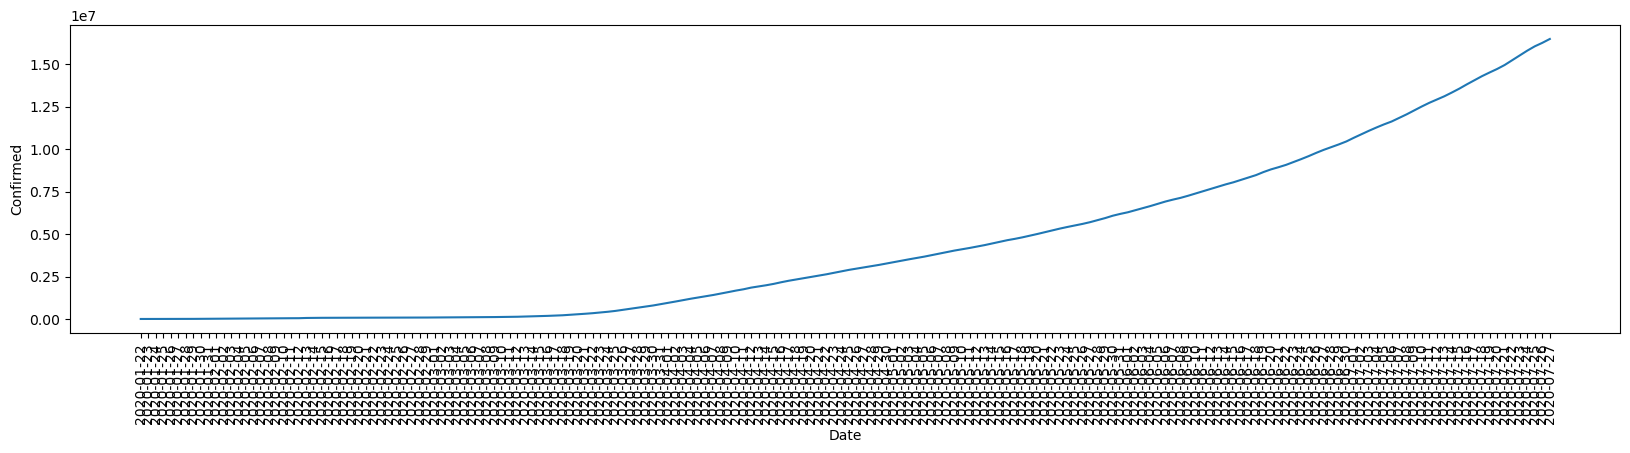

In [13]:
plt.figure(figsize=(20,4))
sns.lineplot(data=Confirmed_cases,x="Date",y="Confirmed")
plt.xticks(rotation=90)
plt.show()

In [15]:
death_cases=df.groupby(["Date"])["Deaths"].sum().reset_index()

In [16]:
death_cases

,Date,Deaths
0,2020-01-22,17
1,2020-01-23,18
2,2020-01-24,26
3,2020-01-25,42
4,2020-01-26,56
...,...,...
183,2020-07-23,633506
184,2020-07-24,639650
185,2020-07-25,644517
186,2020-07-26,648621


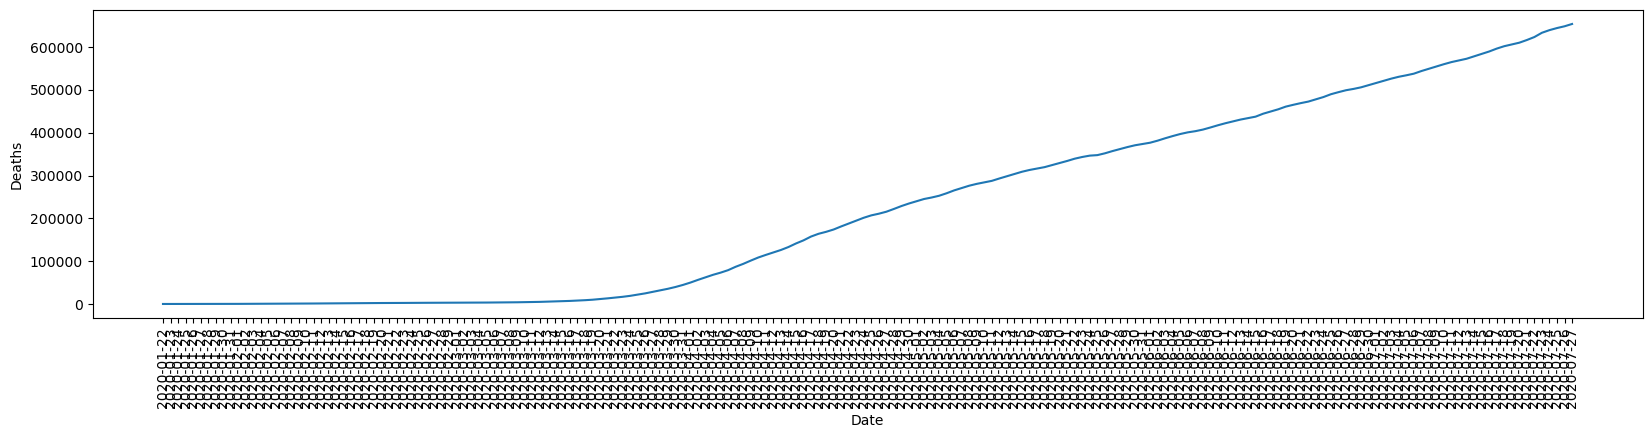

In [19]:
plt.figure(figsize=(20,4))
sns.lineplot(data=death_cases,x="Date",y="Deaths")
plt.xticks(rotation=90)
plt.show()

In [20]:
Recovered_cases=df.groupby(["Date"])["Recovered"].sum().reset_index()
Recovered_cases

,Date,Recovered
0,2020-01-22,28
1,2020-01-23,30
2,2020-01-24,36
3,2020-01-25,39
4,2020-01-26,52
...,...,...
183,2020-07-23,8710969
184,2020-07-24,8939705
185,2020-07-25,9158743
186,2020-07-26,9293464


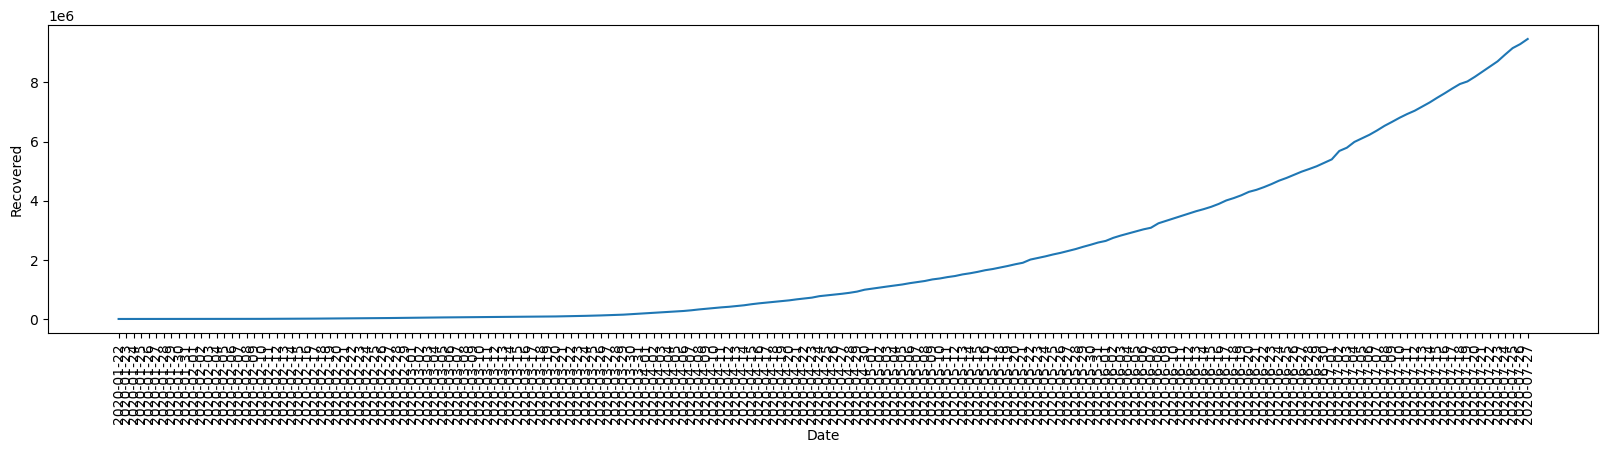

In [21]:
plt.figure(figsize=(20,4))
sns.lineplot(data=Recovered_cases,x="Date",y="Recovered")
plt.xticks(rotation=90)
plt.show()

In [22]:
Active_cases=df.groupby(["Date"])["Active"].sum().reset_index()
Active_cases

,Date,Active
0,2020-01-22,510
1,2020-01-23,606
2,2020-01-24,879
3,2020-01-25,1353
4,2020-01-26,2010
...,...,...
183,2020-07-23,6166006
184,2020-07-24,6212290
185,2020-07-25,6243930
186,2020-07-26,6309711


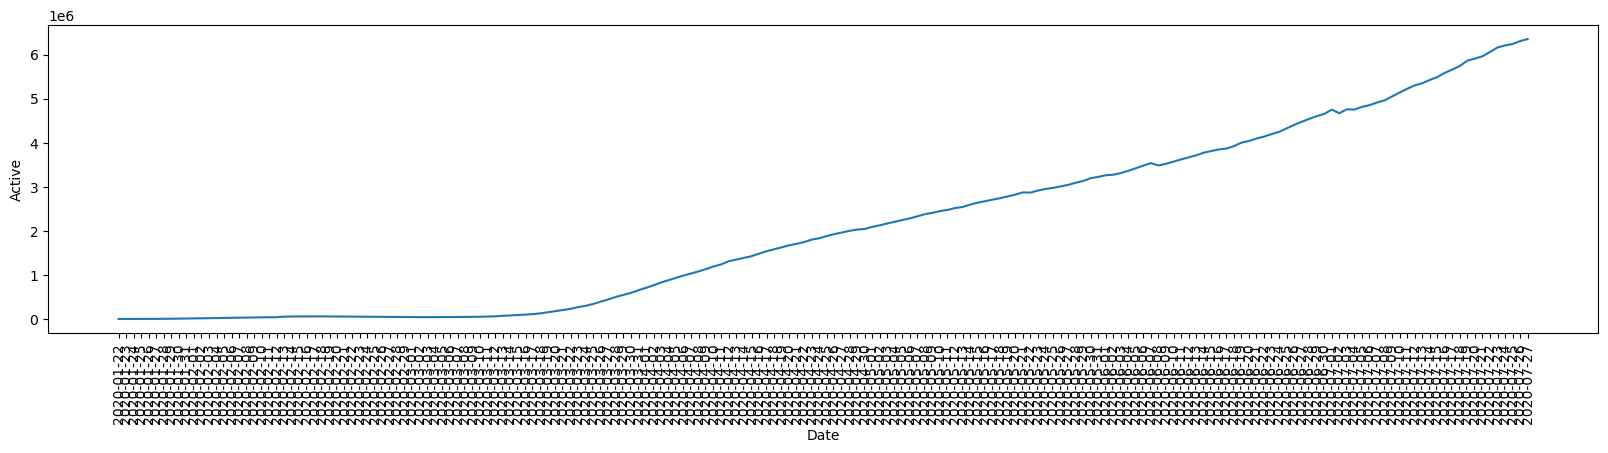

In [23]:
plt.figure(figsize=(20,4))
sns.lineplot(data=Active_cases,x="Date",y="Active")
plt.xticks(rotation=90)
plt.show()

<Figure size 2000x1000 with 0 Axes>

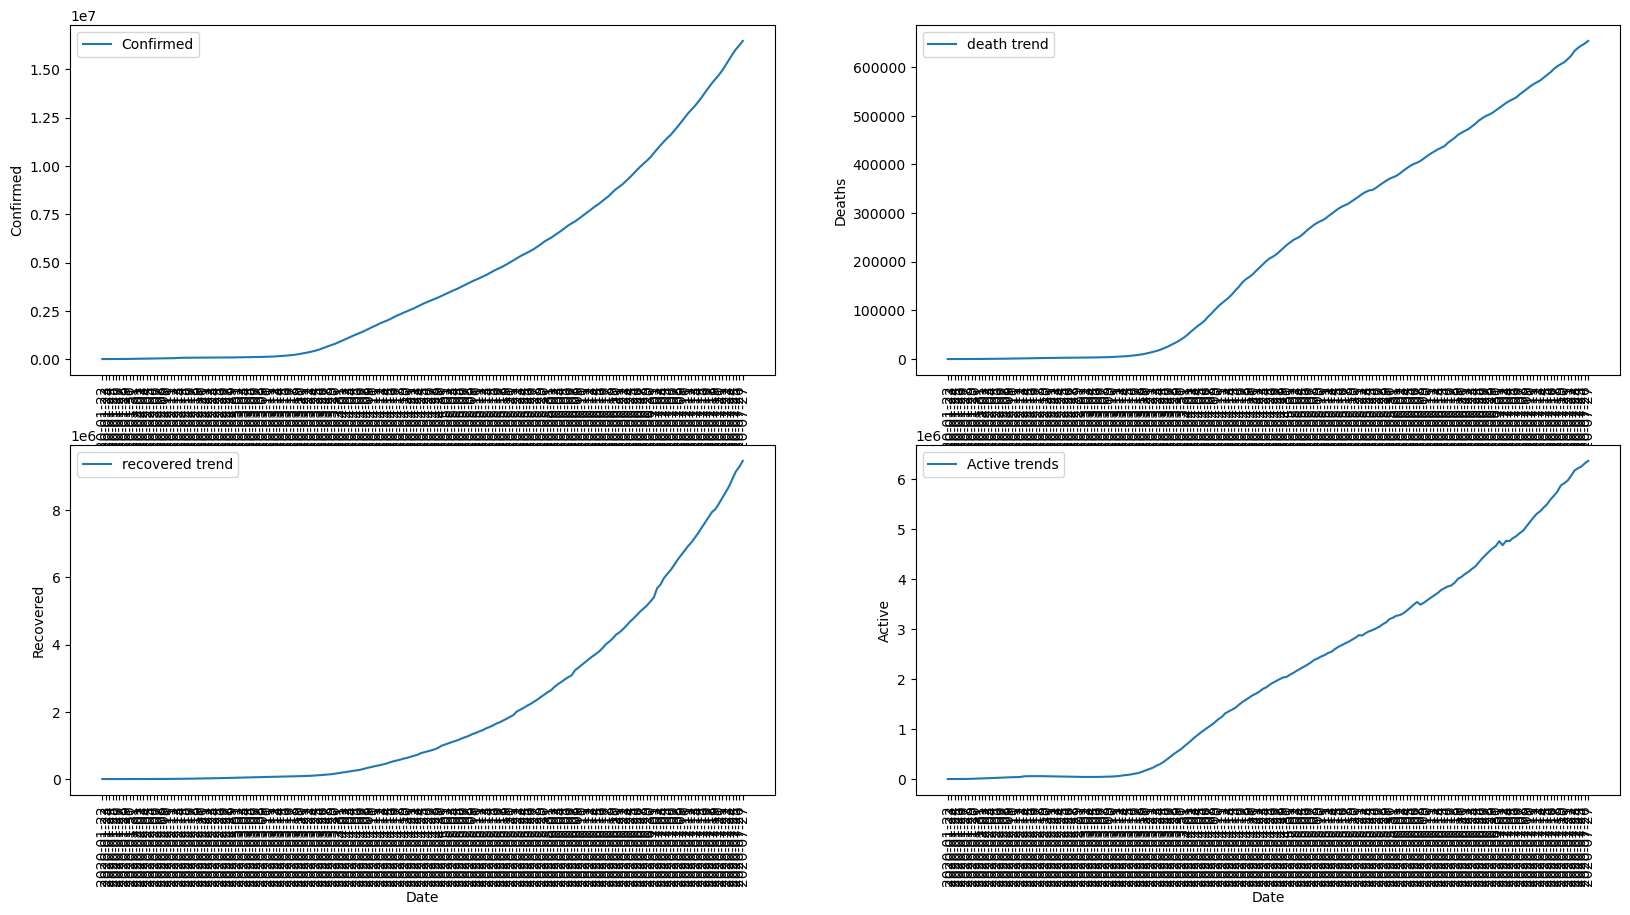

In [157]:
plt.figure(figsize=(20,10))
plt.subplots(2,2,figsize=(20,10))

plt.subplot(2,2,1)
sns.lineplot(data=Confirmed_cases,x="Date",y="Confirmed",label="Confirmed")
plt.xticks(rotation=90)

plt.subplot(2,2,2)
sns.lineplot(data=death_cases,x="Date",y="Deaths",label="death trend")
plt.xticks(rotation=90)

plt.subplot(2,2,3)
sns.lineplot(data=Recovered_cases,x="Date",y="Recovered",label="recovered trend")
plt.xticks(rotation=90)


plt.subplot(2,2,4)
sns.lineplot(data=Active_cases,x="Date",y="Active",label="Active trends")
plt.xticks(rotation=90)
plt.legend()
plt.show()


In [24]:
data_countries=df.groupby("Country")[["Confirmed","Deaths","Recovered","Active"]].sum().reset_index()
data_countries

,Country,Confirmed,Deaths,Recovered,Active
0,Afghanistan,1936390,49098,798240,1089052
1,Albania,196702,5708,118877,72117
2,Algeria,1179755,77972,755897,345886
3,Andorra,94404,5423,69074,19907
4,Angola,22662,1078,6573,15011
...,...,...,...,...,...
182,West Bank and Gaza,233461,1370,61124,170967
183,Western Sahara,901,63,648,190
184,Yemen,67180,17707,23779,25694
185,Zambia,129421,2643,83611,43167


In [26]:
top3_confirmed=data_countries.sort_values(by="Confirmed",ascending=False).head(3)
top3_confirmed

,Country,Confirmed,Deaths,Recovered,Active
173,US,224345948,11011411,56353416,156981121
23,Brazil,89524967,3938034,54492873,31094060
138,Russia,45408411,619385,25120448,19668578


In [28]:
top3_death=data_countries.sort_values(by="Deaths",ascending=False).head(3)
top3_death

,Country,Confirmed,Deaths,Recovered,Active
173,US,224345948,11011411,56353416,156981121
177,United Kingdom,26748587,3997775,126217,22624595
23,Brazil,89524967,3938034,54492873,31094060


In [31]:
top3_Recovered=data_countries.sort_values(by="Recovered",ascending=False).head(3)
top3_Recovered

,Country,Confirmed,Deaths,Recovered,Active
173,US,224345948,11011411,56353416,156981121
23,Brazil,89524967,3938034,54492873,31094060
138,Russia,45408411,619385,25120448,19668578


In [32]:
top3_Active=data_countries.sort_values(by="Active",ascending=False).head(3)
top3_Active

,Country,Confirmed,Deaths,Recovered,Active
173,US,224345948,11011411,56353416,156981121
23,Brazil,89524967,3938034,54492873,31094060
177,United Kingdom,26748587,3997775,126217,22624595


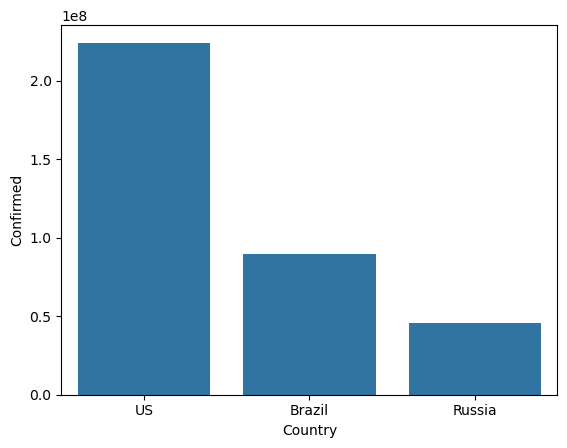

In [35]:
sns.barplot(data=top3_confirmed,x="Country",y="Confirmed")
plt.show()

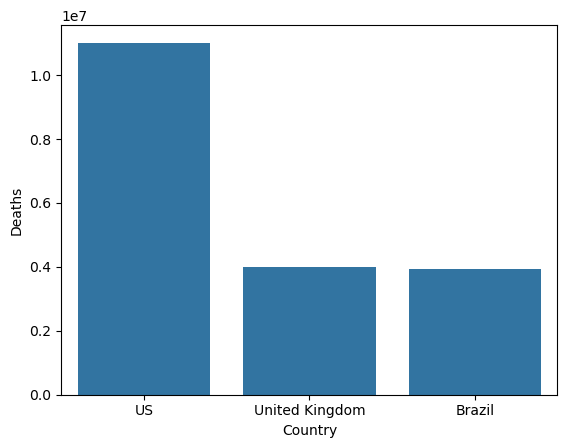

In [37]:
sns.barplot(data=top3_death,x="Country",y="Deaths")
plt.show()

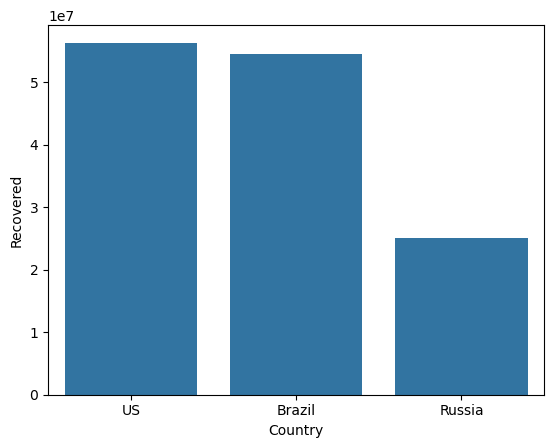

In [38]:
sns.barplot(data=top3_Recovered,x="Country",y="Recovered")
plt.show()

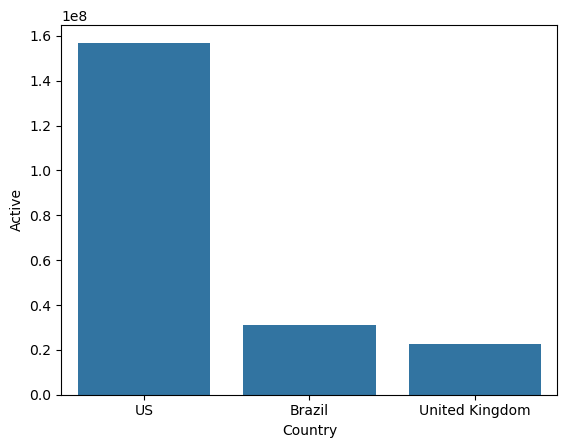

In [39]:
sns.barplot(data=top3_Active,x="Country",y="Active")
plt.show()

In [43]:
data_us=df[df["Country"]=="US"]
data_us

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
223,NaN,US,40.0,-100.0,2020-01-22,1,0,0,1,Americas
484,NaN,US,40.0,-100.0,2020-01-23,1,0,0,1,Americas
745,NaN,US,40.0,-100.0,2020-01-24,2,0,0,2,Americas
1006,NaN,US,40.0,-100.0,2020-01-25,2,0,0,2,Americas
1267,NaN,US,40.0,-100.0,2020-01-26,5,0,0,5,Americas
...,...,...,...,...,...,...,...,...,...,...
47986,NaN,US,40.0,-100.0,2020-07-23,4038816,144430,1233269,2661117,Americas
48247,NaN,US,40.0,-100.0,2020-07-24,4112531,145560,1261624,2705347,Americas
48508,NaN,US,40.0,-100.0,2020-07-25,4178970,146465,1279414,2753091,Americas
48769,NaN,US,40.0,-100.0,2020-07-26,4233923,146935,1297863,2789125,Americas


In [44]:
data_brazil=df[df["Country"]=="Brazil"]
data_brazil

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
28,NaN,Brazil,-14.235,-51.9253,2020-01-22,0,0,0,0,Americas
289,NaN,Brazil,-14.235,-51.9253,2020-01-23,0,0,0,0,Americas
550,NaN,Brazil,-14.235,-51.9253,2020-01-24,0,0,0,0,Americas
811,NaN,Brazil,-14.235,-51.9253,2020-01-25,0,0,0,0,Americas
1072,NaN,Brazil,-14.235,-51.9253,2020-01-26,0,0,0,0,Americas
...,...,...,...,...,...,...,...,...,...,...
47791,NaN,Brazil,-14.235,-51.9253,2020-07-23,2287475,84082,1620313,583080,Americas
48052,NaN,Brazil,-14.235,-51.9253,2020-07-24,2343366,85238,1693214,564914,Americas
48313,NaN,Brazil,-14.235,-51.9253,2020-07-25,2394513,86449,1785359,522705,Americas
48574,NaN,Brazil,-14.235,-51.9253,2020-07-26,2419091,87004,1812913,519174,Americas


In [46]:
data_russ=df[df["Country"]=="Russia"]
data_russ.head()

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
185,NaN,Russia,61.52401,105.318756,2020-01-22,0,0,0,0,Europe
446,NaN,Russia,61.52401,105.318756,2020-01-23,0,0,0,0,Europe
707,NaN,Russia,61.52401,105.318756,2020-01-24,0,0,0,0,Europe
968,NaN,Russia,61.52401,105.318756,2020-01-25,0,0,0,0,Europe
1229,NaN,Russia,61.52401,105.318756,2020-01-26,0,0,0,0,Europe


In [47]:
data_kingdom=df[df["Country"]=="United Kingdom"]
data_kingdom.head()

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
215,Bermuda,United Kingdom,32.3078,-64.7505,2020-01-22,0,0,0,0,Europe
216,Cayman Islands,United Kingdom,19.3133,-81.2546,2020-01-22,0,0,0,0,Europe
217,Channel Islands,United Kingdom,49.3723,-2.3644,2020-01-22,0,0,0,0,Europe
218,Gibraltar,United Kingdom,36.1408,-5.3536,2020-01-22,0,0,0,0,Europe
219,Isle of Man,United Kingdom,54.2361,-4.5481,2020-01-22,0,0,0,0,Europe


In [49]:
us=data_us.groupby("Date")[["Confirmed","Deaths","Active","Recovered"]].sum().reset_index()
us

,Date,Confirmed,Deaths,Active,Recovered
0,2020-01-22,1,0,1,0
1,2020-01-23,1,0,1,0
2,2020-01-24,2,0,2,0
3,2020-01-25,2,0,2,0
4,2020-01-26,5,0,5,0
...,...,...,...,...,...
183,2020-07-23,4038816,144430,2661117,1233269
184,2020-07-24,4112531,145560,2705347,1261624
185,2020-07-25,4178970,146465,2753091,1279414
186,2020-07-26,4233923,146935,2789125,1297863


In [50]:
brazil=data_brazil.groupby("Date")[["Confirmed","Deaths","Active","Recovered"]].sum().reset_index()
brazil

,Date,Confirmed,Deaths,Active,Recovered
0,2020-01-22,0,0,0,0
1,2020-01-23,0,0,0,0
2,2020-01-24,0,0,0,0
3,2020-01-25,0,0,0,0
4,2020-01-26,0,0,0,0
...,...,...,...,...,...
183,2020-07-23,2287475,84082,583080,1620313
184,2020-07-24,2343366,85238,564914,1693214
185,2020-07-25,2394513,86449,522705,1785359
186,2020-07-26,2419091,87004,519174,1812913


In [51]:
russ=data_russ.groupby("Date")[["Confirmed","Deaths","Active","Recovered"]].sum().reset_index()
russ

,Date,Confirmed,Deaths,Active,Recovered
0,2020-01-22,0,0,0,0
1,2020-01-23,0,0,0,0
2,2020-01-24,0,0,0,0
3,2020-01-25,0,0,0,0
4,2020-01-26,0,0,0,0
...,...,...,...,...,...
183,2020-07-23,793720,12873,201552,579295
184,2020-07-24,799499,13026,198745,587728
185,2020-07-25,805332,13172,196096,596064
186,2020-07-26,811073,13249,198652,599172


In [52]:
kingdom=data_kingdom.groupby("Date")[["Confirmed","Deaths","Active","Recovered"]].sum().reset_index()
kingdom

,Date,Confirmed,Deaths,Active,Recovered
0,2020-01-22,0,0,0,0
1,2020-01-23,0,0,0,0
2,2020-01-24,0,0,0,0
3,2020-01-25,0,0,0,0
4,2020-01-26,0,0,0,0
...,...,...,...,...,...
183,2020-07-23,298731,45639,251667,1425
184,2020-07-24,299500,45762,252313,1425
185,2020-07-25,300270,45823,253020,1427
186,2020-07-26,301020,45837,253749,1434


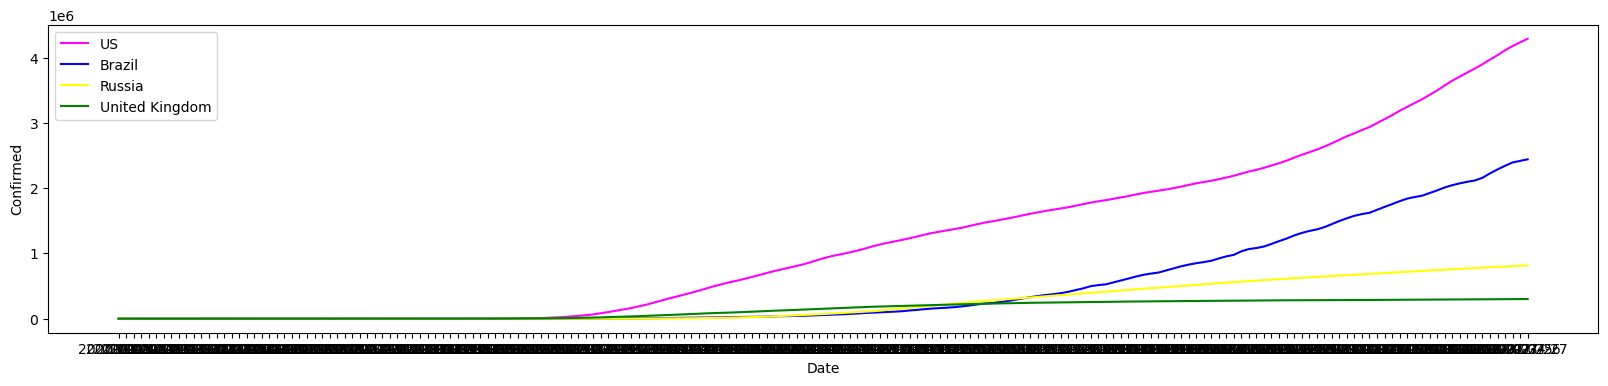

In [56]:
plt.figure(figsize=(20,4))
sns.lineplot(data=us,x="Date",y="Confirmed",color="magenta",label="US")
sns.lineplot(data=brazil,x="Date",y="Confirmed",color="blue",label="Brazil")
sns.lineplot(data=russ,x="Date",y="Confirmed",color="yellow",label="Russia")
sns.lineplot(data=kingdom,x="Date",y="Confirmed",color="green",label="United Kingdom")
plt.legend()
plt.show()

In [57]:
from prophet import Prophet

In [60]:
Confirmed_cases.head()

,Date,Confirmed
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118


In [63]:
death_cases.head()

,Date,Deaths
0,2020-01-22,17
1,2020-01-23,18
2,2020-01-24,26
3,2020-01-25,42
4,2020-01-26,56


In [64]:
Active_cases.head()

,Date,Active
0,2020-01-22,510
1,2020-01-23,606
2,2020-01-24,879
3,2020-01-25,1353
4,2020-01-26,2010


In [66]:
Recovered_cases.head()

,Date,Recovered
0,2020-01-22,28
1,2020-01-23,30
2,2020-01-24,36
3,2020-01-25,39
4,2020-01-26,52


In [76]:
prophet_confirmed_data=Confirmed_cases.rename(columns={"Date":"ds","Confirmed":"y"})
prophet_confirmed_data

,ds,y
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118
...,...,...
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796


In [77]:
model=Prophet()

In [78]:
model.fit(prophet_confirmed_data)

19:03:55 - cmdstanpy - INFO - Chain [1] start processing
19:03:55 - cmdstanpy - INFO - Chain [1] done processing


In [79]:
future=model.make_future_dataframe(periods=7)
future

,ds
0,2020-01-22
1,2020-01-23
2,2020-01-24
3,2020-01-25
4,2020-01-26
...,...
190,2020-07-30
191,2020-07-31
192,2020-08-01
193,2020-08-02


In [80]:
forecast=model.predict(future)
forecast

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2020-01-22,-9.356181e+03,-1.170255e+05,9.282904e+04,-9.356181e+03,-9.356181e+03,-10986.215104,-10986.215104,-10986.215104,-10986.215104,-10986.215104,-10986.215104,0.0,0.0,0.0,-2.034240e+04
1,2020-01-23,-6.667726e+03,-1.227508e+05,9.154154e+04,-6.667726e+03,-6.667726e+03,-1078.892495,-1078.892495,-1078.892495,-1078.892495,-1078.892495,-1078.892495,0.0,0.0,0.0,-7.746619e+03
2,2020-01-24,-3.979272e+03,-9.940163e+04,1.043291e+05,-3.979272e+03,-3.979272e+03,10103.254163,10103.254163,10103.254163,10103.254163,10103.254163,10103.254163,0.0,0.0,0.0,6.123982e+03
3,2020-01-25,-1.290817e+03,-8.559704e+04,1.155941e+05,-1.290817e+03,-1.290817e+03,13670.219215,13670.219215,13670.219215,13670.219215,13670.219215,13670.219215,0.0,0.0,0.0,1.237940e+04
4,2020-01-26,1.397637e+03,-9.654593e+04,1.074290e+05,1.397637e+03,1.397637e+03,7218.147794,7218.147794,7218.147794,7218.147794,7218.147794,7218.147794,0.0,0.0,0.0,8.615785e+03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,2020-07-30,1.674928e+07,1.663756e+07,1.684134e+07,1.674422e+07,1.675309e+07,-1078.892495,-1078.892495,-1078.892495,-1078.892495,-1078.892495,-1078.892495,0.0,0.0,0.0,1.674820e+07
191,2020-07-31,1.695352e+07,1.685728e+07,1.707224e+07,1.694400e+07,1.696388e+07,10103.254163,10103.254163,10103.254163,10103.254163,10103.254163,10103.254163,0.0,0.0,0.0,1.696362e+07
192,2020-08-01,1.715776e+07,1.706374e+07,1.728703e+07,1.714127e+07,1.717603e+07,13670.219215,13670.219215,13670.219215,13670.219215,13670.219215,13670.219215,0.0,0.0,0.0,1.717143e+07
193,2020-08-02,1.736200e+07,1.725936e+07,1.748397e+07,1.733687e+07,1.738844e+07,7218.147794,7218.147794,7218.147794,7218.147794,7218.147794,7218.147794,0.0,0.0,0.0,1.736922e+07


In [82]:
forecast[["yhat_lower","yhat_upper","yhat"]]

,yhat_lower,yhat_upper,yhat
0,-1.170255e+05,9.282904e+04,-2.034240e+04
1,-1.227508e+05,9.154154e+04,-7.746619e+03
2,-9.940163e+04,1.043291e+05,6.123982e+03
3,-8.559704e+04,1.155941e+05,1.237940e+04
4,-9.654593e+04,1.074290e+05,8.615785e+03
...,...,...,...
190,1.663756e+07,1.684134e+07,1.674820e+07
191,1.685728e+07,1.707224e+07,1.696362e+07
192,1.706374e+07,1.728703e+07,1.717143e+07
193,1.725936e+07,1.748397e+07,1.736922e+07


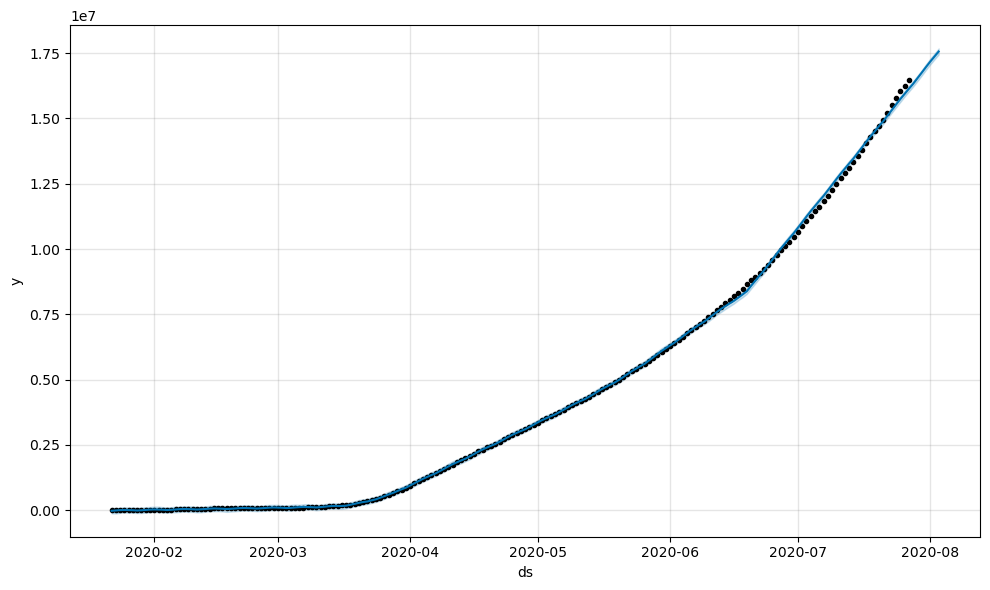

In [83]:
model.plot(forecast)
plt.show()

In [85]:
death_cases

,Date,Deaths
0,2020-01-22,17
1,2020-01-23,18
2,2020-01-24,26
3,2020-01-25,42
4,2020-01-26,56
...,...,...
183,2020-07-23,633506
184,2020-07-24,639650
185,2020-07-25,644517
186,2020-07-26,648621


In [87]:
prophet_death_data=death_cases.rename(columns={"Date":"ds","Deaths":"y"})
prophet_death_data

,ds,y
0,2020-01-22,17
1,2020-01-23,18
2,2020-01-24,26
3,2020-01-25,42
4,2020-01-26,56
...,...,...
183,2020-07-23,633506
184,2020-07-24,639650
185,2020-07-25,644517
186,2020-07-26,648621


In [88]:
model2=Prophet()

In [89]:
model2.fit(prophet_death_data)

19:08:23 - cmdstanpy - INFO - Chain [1] start processing
19:08:23 - cmdstanpy - INFO - Chain [1] done processing


In [90]:
future=model2.make_future_dataframe(periods=7)
future

,ds
0,2020-01-22
1,2020-01-23
2,2020-01-24
3,2020-01-25
4,2020-01-26
...,...
190,2020-07-30
191,2020-07-31
192,2020-08-01
193,2020-08-02


In [91]:
forecast2=model2.predict(future)
forecast2

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2020-01-22,-521.770784,-2667.135015,1182.263119,-521.770784,-521.770784,-191.377481,-191.377481,-191.377481,-191.377481,-191.377481,-191.377481,0.0,0.0,0.0,-713.148265
1,2020-01-23,-432.731501,-1984.831804,1942.335748,-432.731501,-432.731501,388.586602,388.586602,388.586602,388.586602,388.586602,388.586602,0.0,0.0,0.0,-44.144900
2,2020-01-24,-343.692219,-1335.288613,2401.708784,-343.692219,-343.692219,874.803913,874.803913,874.803913,874.803913,874.803913,874.803913,0.0,0.0,0.0,531.111694
3,2020-01-25,-254.652937,-1479.665305,2386.877040,-254.652937,-254.652937,727.302005,727.302005,727.302005,727.302005,727.302005,727.302005,0.0,0.0,0.0,472.649068
4,2020-01-26,-165.613654,-2300.345935,1680.250672,-165.613654,-165.613654,-165.700009,-165.700009,-165.700009,-165.700009,-165.700009,-165.700009,0.0,0.0,0.0,-331.313663
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,2020-07-30,663132.991110,661413.532846,665648.932315,662798.706024,663479.624218,388.586602,388.586602,388.586602,388.586602,388.586602,388.586602,0.0,0.0,0.0,663521.577712
191,2020-07-31,668163.993407,666768.446394,671287.353938,667394.514281,668907.989323,874.803913,874.803913,874.803913,874.803913,874.803913,874.803913,0.0,0.0,0.0,669038.797320
192,2020-08-01,673194.995704,671331.214108,676433.244688,671997.775482,674358.025540,727.302005,727.302005,727.302005,727.302005,727.302005,727.302005,0.0,0.0,0.0,673922.297709
193,2020-08-02,678225.998001,675331.243154,680737.603322,676607.697544,679835.650317,-165.700009,-165.700009,-165.700009,-165.700009,-165.700009,-165.700009,0.0,0.0,0.0,678060.297992


In [135]:
forecast2[["yhat_lower","yhat_upper","yhat"]]

,yhat_lower,yhat_upper,yhat
0,-2667.135015,1182.263119,-713.148265
1,-1984.831804,1942.335748,-44.144900
2,-1335.288613,2401.708784,531.111694
3,-1479.665305,2386.877040,472.649068
4,-2300.345935,1680.250672,-331.313663
...,...,...,...
190,661413.532846,665648.932315,663521.577712
191,666768.446394,671287.353938,669038.797320
192,671331.214108,676433.244688,673922.297709
193,675331.243154,680737.603322,678060.297992


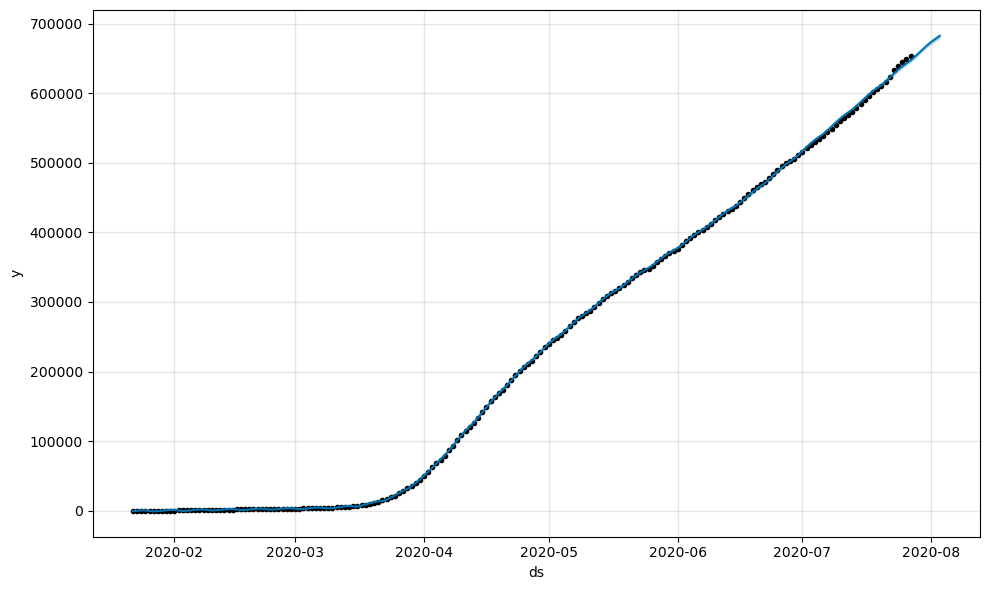

In [136]:
model2.plot(forecast2)
plt.show()

In [105]:
Active_cases

,Date,Active
0,2020-01-22,510
1,2020-01-23,606
2,2020-01-24,879
3,2020-01-25,1353
4,2020-01-26,2010
...,...,...
183,2020-07-23,6166006
184,2020-07-24,6212290
185,2020-07-25,6243930
186,2020-07-26,6309711


In [106]:
prophet_active_data=Active_cases.rename(columns={"Date":"ds","Active":"y"})
prophet_active_data

,ds,y
0,2020-01-22,510
1,2020-01-23,606
2,2020-01-24,879
3,2020-01-25,1353
4,2020-01-26,2010
...,...,...
183,2020-07-23,6166006
184,2020-07-24,6212290
185,2020-07-25,6243930
186,2020-07-26,6309711


In [107]:
model3=Prophet()

In [108]:
model3.fit(prophet_active_data)

19:15:20 - cmdstanpy - INFO - Chain [1] start processing
19:15:20 - cmdstanpy - INFO - Chain [1] done processing


In [109]:
future=model3.make_future_dataframe(periods=7)
future

,ds
0,2020-01-22
1,2020-01-23
2,2020-01-24
3,2020-01-25
4,2020-01-26
...,...
190,2020-07-30
191,2020-07-31
192,2020-08-01
193,2020-08-02


In [137]:
forecast3=model3.predict(future)
forecast3

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2020-01-22,3.938641e+02,-4.712706e+04,3.873231e+04,3.938641e+02,3.938641e+02,-5768.245993,-5768.245993,-5768.245993,-5768.245993,-5768.245993,-5768.245993,0.0,0.0,0.0,-5.374382e+03
1,2020-01-23,2.179134e+03,-4.477098e+04,4.546122e+04,2.179134e+03,2.179134e+03,-2565.782696,-2565.782696,-2565.782696,-2565.782696,-2565.782696,-2565.782696,0.0,0.0,0.0,-3.866492e+02
2,2020-01-24,3.964403e+03,-3.886371e+04,5.404063e+04,3.964403e+03,3.964403e+03,3219.381401,3219.381401,3219.381401,3219.381401,3219.381401,3219.381401,0.0,0.0,0.0,7.183784e+03
3,2020-01-25,5.749672e+03,-3.781777e+04,5.425906e+04,5.749672e+03,5.749672e+03,3129.568400,3129.568400,3129.568400,3129.568400,3129.568400,3129.568400,0.0,0.0,0.0,8.879241e+03
4,2020-01-26,7.534942e+03,-2.956834e+04,6.314828e+04,7.534942e+03,7.534942e+03,8182.557299,8182.557299,8182.557299,8182.557299,8182.557299,8182.557299,0.0,0.0,0.0,1.571750e+04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,2020-07-30,6.483578e+06,6.436356e+06,6.523556e+06,6.480178e+06,6.486732e+06,-2565.782696,-2565.782696,-2565.782696,-2565.782696,-2565.782696,-2565.782696,0.0,0.0,0.0,6.481012e+06
191,2020-07-31,6.545831e+06,6.501008e+06,6.599228e+06,6.539828e+06,6.552053e+06,3219.381401,3219.381401,3219.381401,3219.381401,3219.381401,3219.381401,0.0,0.0,0.0,6.549050e+06
192,2020-08-01,6.608084e+06,6.563664e+06,6.660580e+06,6.598467e+06,6.617742e+06,3129.568400,3129.568400,3129.568400,3129.568400,3129.568400,3129.568400,0.0,0.0,0.0,6.611213e+06
193,2020-08-02,6.670337e+06,6.626814e+06,6.727096e+06,6.656020e+06,6.685135e+06,8182.557299,8182.557299,8182.557299,8182.557299,8182.557299,8182.557299,0.0,0.0,0.0,6.678519e+06


In [111]:
forecast3[["yhat_lower","yhat_upper","yhat"]]

,yhat_lower,yhat_upper,yhat
0,-5.011538e+04,4.209298e+04,-5.374382e+03
1,-4.929261e+04,4.595820e+04,-3.866492e+02
2,-3.745253e+04,5.665836e+04,7.183784e+03
3,-3.960246e+04,5.307356e+04,8.879241e+03
4,-3.160528e+04,6.360602e+04,1.571750e+04
...,...,...,...
190,6.435764e+06,6.528225e+06,6.481012e+06
191,6.502450e+06,6.595610e+06,6.549050e+06
192,6.562880e+06,6.658375e+06,6.611213e+06
193,6.630844e+06,6.727702e+06,6.678519e+06


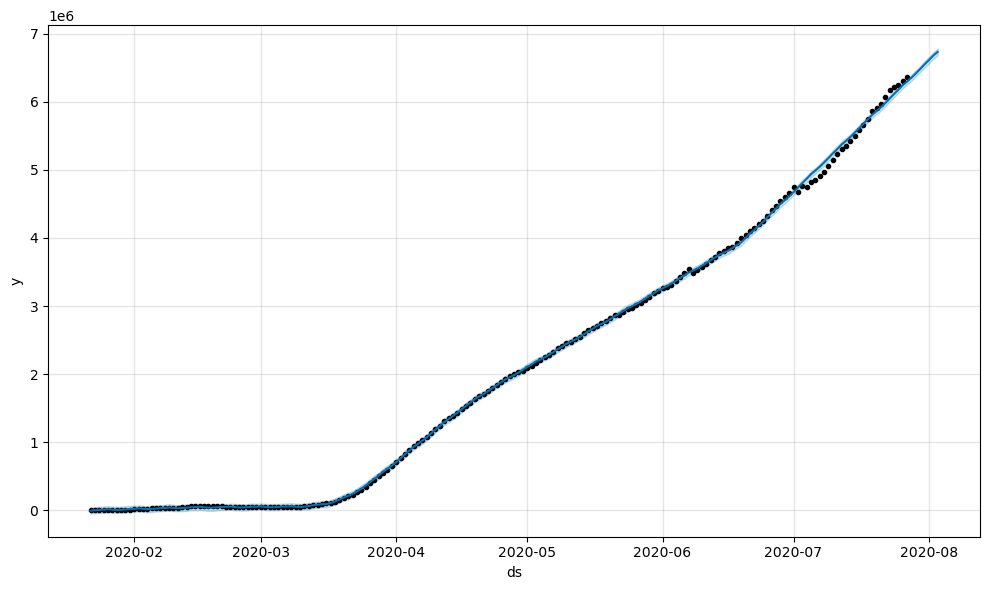

In [138]:
model3.plot(forecast3)
plt.show()

In [127]:
Recovered_cases

,Date,Recovered
0,2020-01-22,28
1,2020-01-23,30
2,2020-01-24,36
3,2020-01-25,39
4,2020-01-26,52
...,...,...
183,2020-07-23,8710969
184,2020-07-24,8939705
185,2020-07-25,9158743
186,2020-07-26,9293464


In [128]:
prophet_recovered_data=Recovered_cases.rename(columns={"Date":"ds","Recovered":"y"})
prophet_recovered_data

,ds,y
0,2020-01-22,28
1,2020-01-23,30
2,2020-01-24,36
3,2020-01-25,39
4,2020-01-26,52
...,...,...
183,2020-07-23,8710969
184,2020-07-24,8939705
185,2020-07-25,9158743
186,2020-07-26,9293464


In [129]:
model4=Prophet()

In [130]:
model4.fit(prophet_recovered_data)

19:19:52 - cmdstanpy - INFO - Chain [1] start processing
19:19:52 - cmdstanpy - INFO - Chain [1] done processing


In [139]:
future4=model4.make_future_dataframe(periods=7)
future4

,ds
0,2020-01-22
1,2020-01-23
2,2020-01-24
3,2020-01-25
4,2020-01-26
...,...
190,2020-07-30
191,2020-07-31
192,2020-08-01
193,2020-08-02


In [132]:
forecast4=model4.predict(future4)
forecast4


,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2020-01-22,-1.205747e+04,-1.031367e+05,6.195759e+04,-1.205747e+04,-1.205747e+04,-4840.306147,-4840.306147,-4840.306147,-4840.306147,-4840.306147,-4840.306147,0.0,0.0,0.0,-1.689777e+04
1,2020-01-23,-1.098613e+04,-8.656421e+04,7.108224e+04,-1.098613e+04,-1.098613e+04,1268.500733,1268.500733,1268.500733,1268.500733,1268.500733,1268.500733,0.0,0.0,0.0,-9.717631e+03
2,2020-01-24,-9.914796e+03,-7.748184e+04,7.866534e+04,-9.914796e+03,-9.914796e+03,6127.043529,6127.043529,6127.043529,6127.043529,6127.043529,6127.043529,0.0,0.0,0.0,-3.787753e+03
3,2020-01-25,-8.843461e+03,-8.023537e+04,8.320411e+04,-8.843461e+03,-8.843461e+03,9721.186705,9721.186705,9721.186705,9721.186705,9721.186705,9721.186705,0.0,0.0,0.0,8.777256e+02
4,2020-01-26,-7.772126e+03,-9.034639e+04,7.231325e+04,-7.772126e+03,-7.772126e+03,-915.435299,-915.435299,-915.435299,-915.435299,-915.435299,-915.435299,0.0,0.0,0.0,-8.687561e+03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,2020-07-30,9.597260e+06,9.519549e+06,9.671852e+06,9.593084e+06,9.601476e+06,1268.500733,1268.500733,1268.500733,1268.500733,1268.500733,1268.500733,0.0,0.0,0.0,9.598529e+06
191,2020-07-31,9.733966e+06,9.665999e+06,9.816863e+06,9.724688e+06,9.742855e+06,6127.043529,6127.043529,6127.043529,6127.043529,6127.043529,6127.043529,0.0,0.0,0.0,9.740093e+06
192,2020-08-01,9.870671e+06,9.795758e+06,9.965061e+06,9.855610e+06,9.884476e+06,9721.186705,9721.186705,9721.186705,9721.186705,9721.186705,9721.186705,0.0,0.0,0.0,9.880392e+06
193,2020-08-02,1.000738e+07,9.921946e+06,1.009144e+07,9.985902e+06,1.002755e+07,-915.435299,-915.435299,-915.435299,-915.435299,-915.435299,-915.435299,0.0,0.0,0.0,1.000646e+07


In [133]:
forecast4[["yhat_lower","yhat_upper","yhat"]]

,yhat_lower,yhat_upper,yhat
0,-1.031367e+05,6.195759e+04,-1.689777e+04
1,-8.656421e+04,7.108224e+04,-9.717631e+03
2,-7.748184e+04,7.866534e+04,-3.787753e+03
3,-8.023537e+04,8.320411e+04,8.777256e+02
4,-9.034639e+04,7.231325e+04,-8.687561e+03
...,...,...,...
190,9.519549e+06,9.671852e+06,9.598529e+06
191,9.665999e+06,9.816863e+06,9.740093e+06
192,9.795758e+06,9.965061e+06,9.880392e+06
193,9.921946e+06,1.009144e+07,1.000646e+07


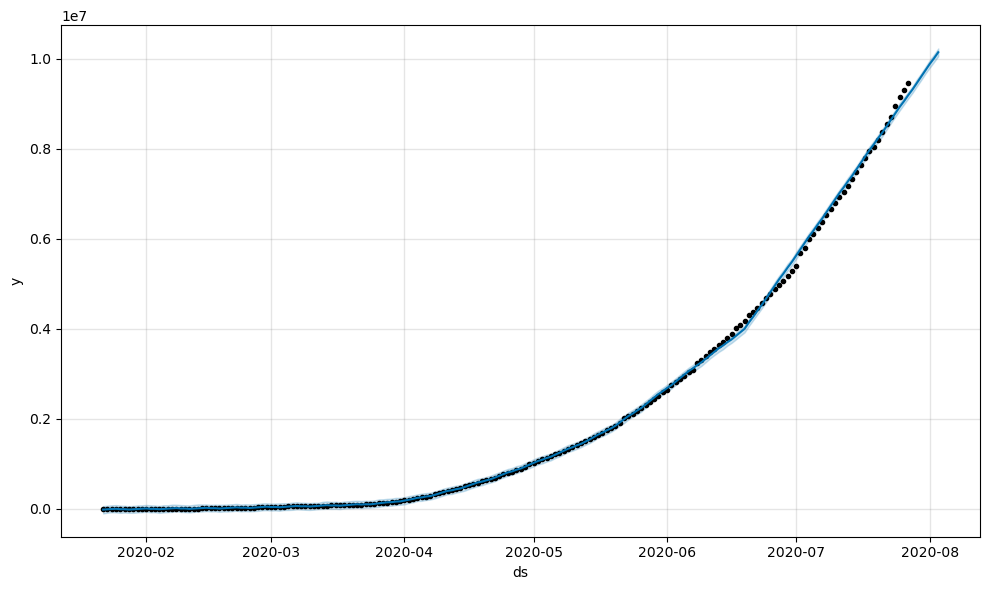

In [134]:
model4.plot(forecast4)
plt.show()

<Figure size 1200x500 with 0 Axes>

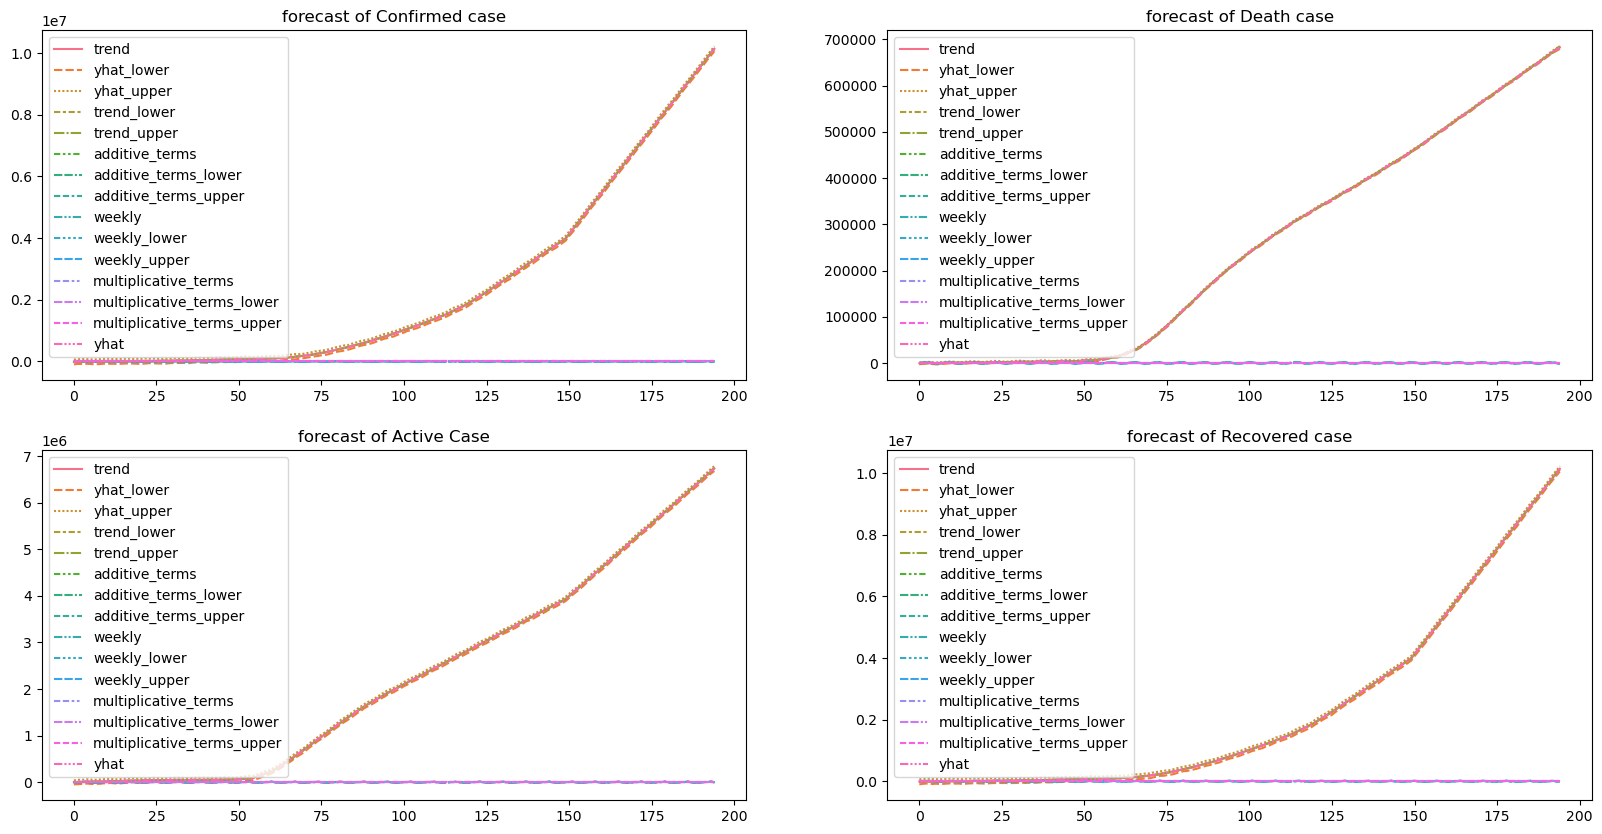

In [153]:
plt.figure(figsize=(12,5))
plt.subplots(2,2 ,figsize=(20,10))

plt.subplot(2,2,1)
sns.lineplot(data=forecast)
plt.title("forecast of Confirmed case")


plt.subplot(2,2,2)
sns.lineplot(data=forecast2)
plt.title("forecast of Death case")

plt.subplot(2,2,3)
sns.lineplot(data=forecast3)
plt.title("forecast of Active Case")

plt.subplot(2,2,4)
sns.lineplot(data=forecast4)
plt.title("forecast of Recovered case")

plt.legend()
plt.show()

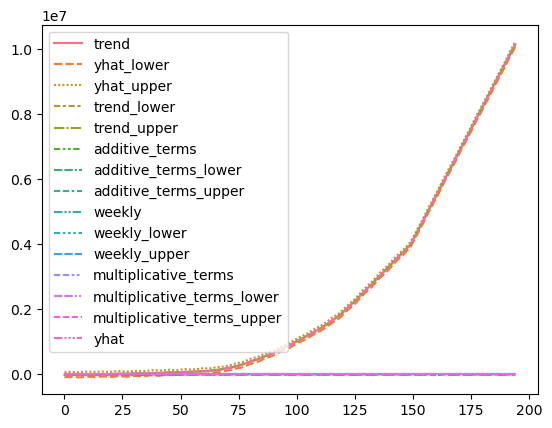

In [144]:
sns.lineplot(forecast)
plt.show()

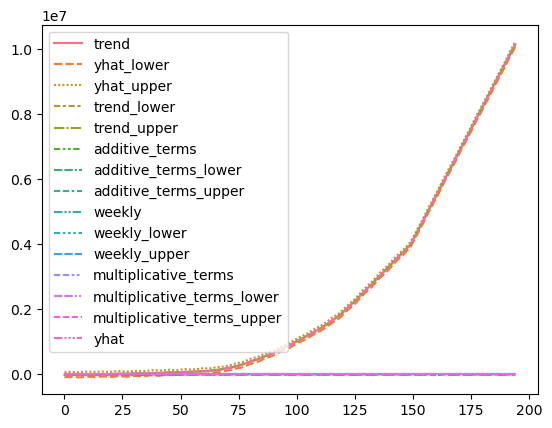

In [144]:
sns.lineplot(forecast)
plt.show()